# Notebook 04: DTU radiometric data, ΔT and measured power loss

**Goal:** use real temperatures (°C) and measured I-V curves on the same faulty modules to answer:
1. How large is ΔT for each fault type?
2. Does the version 1 power-loss model (bypass-diode topology: 0 / 33 / 67 / 100 %) match measured power?
3. Is ΔT (or hot area) related to the power that is actually lost?
4. How do irradiance and drone altitude affect ΔT? (IEC TS 62446-3 / IEA Task 13 recommend > 600 W/m²)

**Data:** DTU PV plant, Drone Infrared Thermography Dataset (CC BY 4.0, DOI 10.11583/DTU.29665346).
43 modules in 7 fault folders, DJI Mavic 3T. Each image is already cropped to one module and stored as a `.raw` file of
temperatures (float32, 605 × 363 pixels). Each image was taken at 4 altitudes (8/10/14/20 m) × 4 irradiance levels
(200 / 600 / 800 / above 800 W/m²). I-V curves are measured at STC (average of 3 flashes).

## 1. Setup and file index

In [1]:
import re, glob, os
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = "archive/DTU/IRT DATASET"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

files = sorted(glob.glob(f"{ROOT}/*/Module */IRT/*.raw"))
idx = []
for f in files:
    fault, module = f.split("/")[-4], f.split("/")[-3]
    name = os.path.basename(f)
    idx.append(dict(fault=fault[3:], module=module, file=f,
                    alt_m=int(re.search(r"_(\d+)m", name).group(1)),
                    irr=re.search(r"_(abv800|200|600|800)(?=[_.\s])", name).group(1)))
idx = pd.DataFrame(idx)
print(len(idx), "temperature images,", idx.groupby(["fault", "module"]).ngroups, "modules")
print(idx.groupby("fault").module.nunique().to_string())

640 temperature images, 43 modules
fault
Cell Cracks                     8
Cell Interconnects              8
Glass Cracks                    2
PID                             6
Short-circuited Bypass Diode    7
Soiling 1                       6
Soiling 2                       6

## 2. Look at one image per fault type
`load_T()` reads a `.raw` file: 605 × 363 numbers, each one a temperature in °C.
Shown at 10 m altitude and the highest irradiance available.

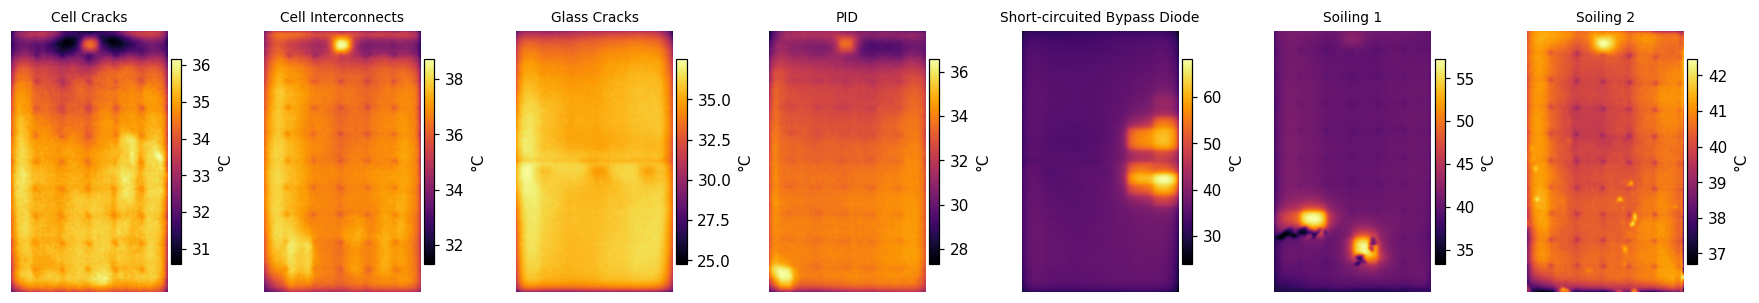

In [2]:
def load_T(path):
    return np.fromfile(path, dtype=np.float32).reshape(605, 363)

faults = sorted(idx.fault.unique())
fig, axes = plt.subplots(1, len(faults), figsize=(2.3 * len(faults), 4))
for ax, fl in zip(axes, faults):
    sub = idx[(idx.fault == fl) & (idx.alt_m == 10)]
    sub = sub[sub.irr == ("abv800" if (sub.irr == "abv800").any() else "800")]
    T = load_T(sub.file.iloc[0])
    im = ax.imshow(T, cmap="inferno"); ax.set_title(fl, fontsize=9); ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.06, pad=0.02, label="°C")
plt.tight_layout(); plt.savefig("figures/dtu_examples.png", dpi=200); plt.show()

## 3. Temperature features for every image
For each image (ignoring a 15-pixel border):
* `T_med`: median module temperature (the "healthy" reference inside the same module)
* `dT_max` = T_max − T_med: the ΔT used in IEC TS 62446-3 style inspections
* `hot_frac`: fraction of the module that is more than 5 K above the median (how **large** the hot area is)

In [3]:
def features(path):
    T = load_T(path)[15:-15, 15:-15]
    med = float(np.median(T))
    return pd.Series(dict(T_med=med, dT_max=float(T.max()) - med,
                          dT_p99=float(np.percentile(T, 99)) - med, hot_frac=float((T > med + 5).mean())))

feat = pd.concat([idx, idx.file.apply(features)], axis=1)
summary_T = (feat[feat.irr.isin(["800", "abv800"])]
             .groupby("fault")[["dT_max", "dT_p99", "hot_frac"]].median().round(2))
print("Median over images at ≥ 800 W/m²:\n", summary_T.to_string())

Median over images at ≥ 800 W/m²:
                               dT_max  dT_p99  hot_frac
fault                                                 
Cell Cracks                     1.34    0.92      0.00
Cell Interconnects              1.94    1.36      0.00
Glass Cracks                    1.73    1.38      0.00
PID                             1.55    1.21      0.00
Short-circuited Bypass Diode   31.70   24.75      0.12
Soiling 1                       2.35    1.33      0.00
Soiling 2                      48.19   32.93      0.05

## 4. Measured power from the I-V curves
`Pmax` = max(V × I). The dataset has two module types (by short-circuit current): type A ≈ 290 W (Isc ≈ 9.7 A) and
type B ≈ 529 W (Isc ≈ 13.4 A).
**Assumption:** there is no healthy reference module in the dataset, so the reference power of each type is the median
`Pmax` of the modules of that type **without** a bypass-diode fault (their losses are within a few %).
Soiling modules are excluded here: their I-V curves were measured in the field, not at STC.

In [4]:
iv = []
for f in sorted(glob.glob(f"{ROOT}/0[1-5]*/Module */*.csv")):
    d = np.genfromtxt(f, delimiter=",", skip_header=1); V, I = d[:, 0], d[:, 1]
    iv.append(dict(fault=f.split("/")[-3][3:], module=f.split("/")[-2], V=V, I=I,
                   Isc=I[0], Voc=V[I > 0].max(), Pmax=(V * I).max()))
iv = pd.DataFrame(iv)
iv["type"] = np.where(iv.Isc > 12, "B", "A")
ref = iv[iv.fault != "Short-circuited Bypass Diode"].groupby("type")[["Pmax", "Voc"]].median()
iv["P_ref"] = iv.type.map(ref.Pmax); iv["Voc_ref"] = iv.type.map(ref.Voc)
iv["loss_pct"] = 100 * (1 - iv.Pmax / iv.P_ref)
print(ref.round(1).to_string())
print(iv[["fault", "module", "type", "Isc", "Voc", "Pmax", "loss_pct"]].round(1).to_string(index=False))

       Pmax   Voc
type             
A     290.9  39.5
B     528.9  49.8
                       fault   module type  Isc  Voc  Pmax  loss_pct
                 Cell Cracks Module 1    A  9.7 39.3 288.5       0.8
                 Cell Cracks Module 2    A  9.8 39.2 286.9       1.4
                 Cell Cracks Module 3    A  9.8 39.5 289.5       0.5
                 Cell Cracks Module 4    A  9.7 39.5 289.8       0.4
                 Cell Cracks Module 5    A  9.7 39.3 291.5      -0.2
                 Cell Cracks Module 6    A  9.8 39.4 291.2      -0.1
                 Cell Cracks Module 7    A  9.7 39.4 292.9      -0.7
                 Cell Cracks Module 8    A  9.8 39.5 290.4       0.2
          Cell Interconnects Module 1    A  9.8 40.0 289.5       0.5
          Cell Interconnects Module 2    A  9.8 39.9 281.2       3.3
          Cell Interconnects Module 3    A  9.7 40.1 265.6       8.7
          Cell Interconnects Module 4    A  9.7 39.6 292.3      -0.5
          Cell Interconnects Mo

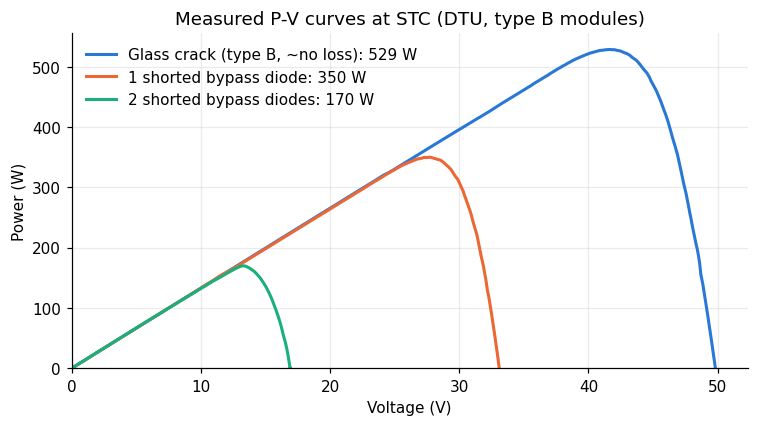

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
for (fl, mod), lab, c in [(("Glass Cracks", "Module 1"), "Glass crack (type B, ~no loss)", BLUE),
                          (("Short-circuited Bypass Diode", "Module 1"), "1 shorted bypass diode", ORANGE),
                          (("Short-circuited Bypass Diode", "Module 3"), "2 shorted bypass diodes", AQUA)]:
    r = iv[(iv.fault == fl) & (iv.module == mod)].iloc[0]
    ax.plot(r.V, r.V * r.I, color=c, lw=2, label=f"{lab}: {r.Pmax:.0f} W")
ax.set_xlabel("Voltage (V)"); ax.set_ylabel("Power (W)"); ax.set_ylim(0); ax.set_xlim(0)
ax.set_title("Measured P-V curves at STC (DTU, type B modules)"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("figures/dtu_pv_curves.png", dpi=200); plt.show()

## 5. Check the version 1 power-loss model (bypass-diode topology)
A module has 3 substrings, each protected by one bypass diode. If *k* diodes are shorted, *k* substrings are bypassed:
the voltage drops to (3 − k)/3 of normal and the power is lost by about k/3.
We estimate k from the measured voltage, k = round(3 × (1 − Voc / Voc_ref)), and compare predicted with measured loss.

In [6]:
bpd = iv[iv.fault == "Short-circuited Bypass Diode"].copy()
bpd["k_shorted"] = (3 * (1 - bpd.Voc / bpd.Voc_ref)).round().astype(int)
bpd["predicted_loss_pct"] = 100 * bpd.k_shorted / 3
bpd["error_pct_points"] = bpd.loss_pct - bpd.predicted_loss_pct
print(bpd[["module", "type", "Voc", "k_shorted", "predicted_loss_pct", "loss_pct", "error_pct_points"]].round(1).to_string(index=False))
print(f"\nMean absolute error: {bpd.error_pct_points.abs().mean():.1f} percentage points")

  module type  Voc  k_shorted  predicted_loss_pct  loss_pct  error_pct_points
Module 1    B 33.0          1                33.3      33.8               0.5
Module 2    B 33.3          1                33.3      33.7               0.4
Module 3    B 16.9          2                66.7      67.9               1.2
Module 4    A 26.2          1                33.3      34.3               0.9
Module 5    A 12.7          2                66.7      68.0               1.3
Module 6    A 26.2          1                33.3      32.5              -0.9
Module 7    A 12.8          2                66.7      67.0               0.3

Mean absolute error: 0.8 percentage points

## 6. Is ΔT related to the power lost?
Module-level values: median of each feature over that module's images at ≥ 800 W/m², joined with its measured loss.

                                                       dT_max  hot_frac  loss_pct
group                                                                            
Bypass diode short                                      32.69      0.12     34.25
Cell-level faults (cracks, interconnects, PID, glass)    1.49      0.00      0.00

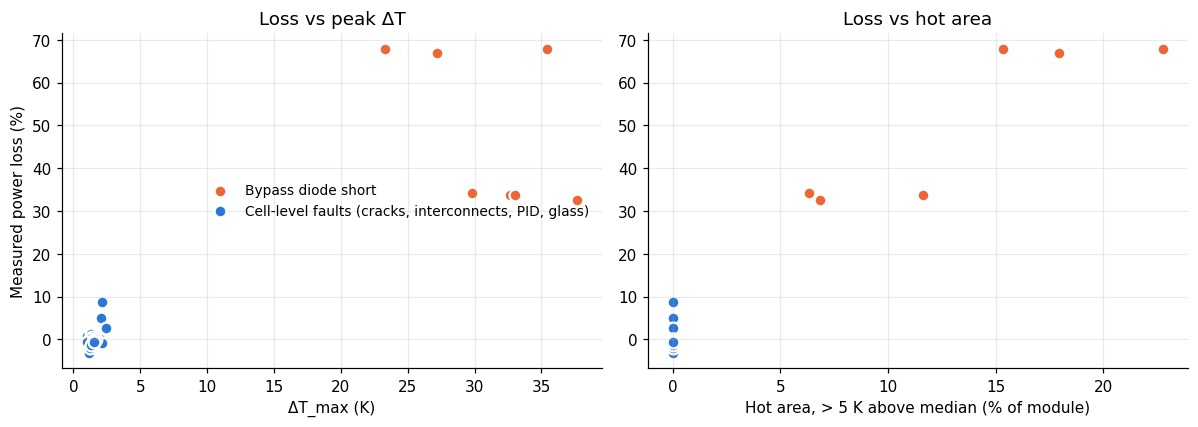

In [7]:
mod_T = (feat[feat.irr.isin(["800", "abv800"])].groupby(["fault", "module"])[["dT_max", "hot_frac"]].median().reset_index())
m = mod_T.merge(iv[["fault", "module", "loss_pct"]], on=["fault", "module"])
m["group"] = np.where(m.fault == "Short-circuited Bypass Diode", "Bypass diode short", "Cell-level faults (cracks, interconnects, PID, glass)")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for g, c in [("Bypass diode short", ORANGE), ("Cell-level faults (cracks, interconnects, PID, glass)", BLUE)]:
    s = m[m.group == g]
    ax[0].scatter(s.dT_max, s.loss_pct, s=60, color=c, label=g, edgecolor="white", linewidth=1.5)
    ax[1].scatter(100 * s.hot_frac, s.loss_pct, s=60, color=c, label=g, edgecolor="white", linewidth=1.5)
ax[0].set_xlabel("ΔT_max (K)"); ax[0].set_ylabel("Measured power loss (%)"); ax[0].set_title("Loss vs peak ΔT")
ax[1].set_xlabel("Hot area, > 5 K above median (% of module)"); ax[1].set_title("Loss vs hot area")
ax[0].legend(frameon=False, fontsize=9, loc="center right")
plt.tight_layout(); plt.savefig("figures/dtu_dT_vs_loss.png", dpi=200); plt.show()
print(m.groupby("group")[["dT_max", "hot_frac", "loss_pct"]].median().round(2).to_string())

## 7. Effect of irradiance and drone altitude on ΔT

irr
200       0.30
600       1.81
800       1.54
abv800    1.54
alt_m
8     1.77
10    1.84
14    1.54
20    1.26

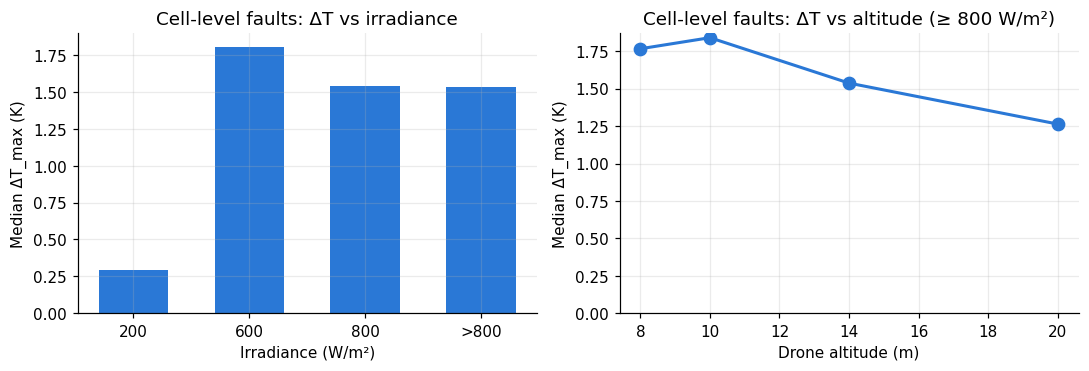

In [8]:
order = ["200", "600", "800", "abv800"]
cell = feat[feat.fault.isin(["Cell Cracks", "Cell Interconnects", "PID", "Glass Cracks"])]
by_irr = cell.groupby("irr").dT_max.median().reindex(order)
by_alt = cell[cell.irr.isin(["800", "abv800"])].groupby("alt_m").dT_max.median()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].bar(["200", "600", "800", ">800"], by_irr.values, color=BLUE, width=0.6)
ax[0].set_xlabel("Irradiance (W/m²)"); ax[0].set_ylabel("Median ΔT_max (K)"); ax[0].set_title("Cell-level faults: ΔT vs irradiance")
ax[1].plot(by_alt.index, by_alt.values, color=BLUE, lw=2, marker="o", markersize=8)
ax[1].set_xlabel("Drone altitude (m)"); ax[1].set_ylabel("Median ΔT_max (K)"); ax[1].set_title("Cell-level faults: ΔT vs altitude (≥ 800 W/m²)")
ax[1].set_ylim(0)
plt.tight_layout(); plt.savefig("figures/dtu_irr_alt.png", dpi=200); plt.show()
print(by_irr.round(2).to_string()); print(by_alt.round(2).to_string())

## 8. Findings
* **Version 1 model confirmed:** modules with 1 shorted bypass diode lose about 33 % and with 2 about 67 %, matching the topology model within about 1 percentage point.
* **Bypass-diode faults are very hot** (ΔT about 25–38 K); cell cracks, interconnects, PID and glass cracks are only about 1–2.5 K and lose at most about 9 %.
* **Hot area follows power loss better than peak ΔT:** 2 shorted diodes give roughly twice the hot area of 1, while peak ΔT is similar.
* **Irradiance matters:** at 200 W/m² ΔT almost disappears, which supports the > 600 W/m² rule. ΔT also decreases with altitude because small hot spots blur.
* **Limitation:** no healthy reference module; reference power = median of modules without bypass-diode faults. Only 7 bypass-diode modules.